# 2 · Periodic repeats with the Fourier transform

The sequence is encoded as 20 indicator channels. For each window and period $p$, the excess score
$E_p \in [0, 1]$ measures the fraction of the window's variance explained by period-$p$ structure
($E_p = 1$ for a perfect repeat). The spectrum proposes periods; string matching verifies them.

In [1]:
import matplotlib.pyplot as plt
from aarepeats import EXAMPLES, read_fasta
from aarepeats import plotting as P

P.use_style()
DATA = "../data"
seq = EXAMPLES["toy"]
print(len(seq), seq)

66 MAMAMAMAMAMAPRTEINSEQENCEAAAAAAHHHHTESTSTSTSTSTSSGSGSGSGSWWWWWGSGS


  1-12  period 2  (MA) x 6.0
 38-48  period 2  (ST) x 5.5
 49-57  period 2  (SG) x 4.5


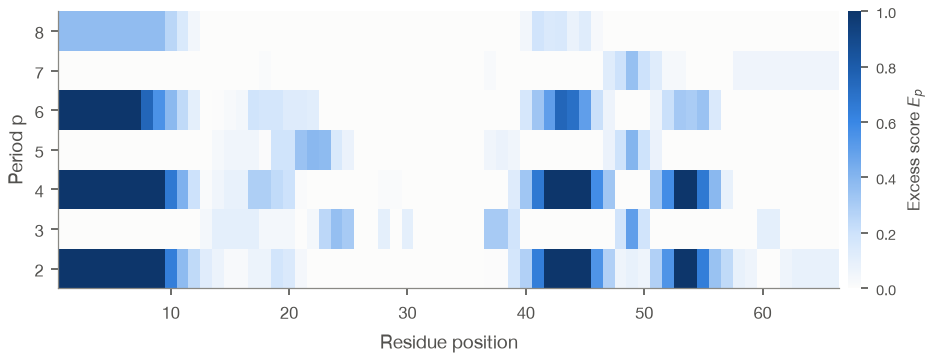

In [2]:
from aarepeats import detect_periodic_repeats, local_periodicity

for r in detect_periodic_repeats(seq, window=8):
    print(f"{r.start + 1:>3}-{r.end:<3} period {r.period}  ({r.unit}) x {r.copies:.1f}")
P.plot_periodicity_map(local_periodicity(seq, 2, 8, window=8))
plt.show()

## Encoding matters: hydropathy barely separates M/A or S/T (relative power at period 2)

In [3]:
from aarepeats import power_spectrum
from aarepeats.scales import AA_SCALES

for name, scale in [("indicator", None), ("Kyte-Doolittle", AA_SCALES["Kyte-Doolittle hydropathy"])]:
    freq, power = power_spectrum(seq, scale)
    print(f"{name:>15}: power at period 2 = {power[-1]:.2f}")

      indicator: power at period 2 = 1.94
 Kyte-Doolittle: power at period 2 = 0.11


## Collagen: Gly-X-Y periodicity without identical units

[(119, 151, 3, 0.33), (187, 1183, 3, 0.33)]


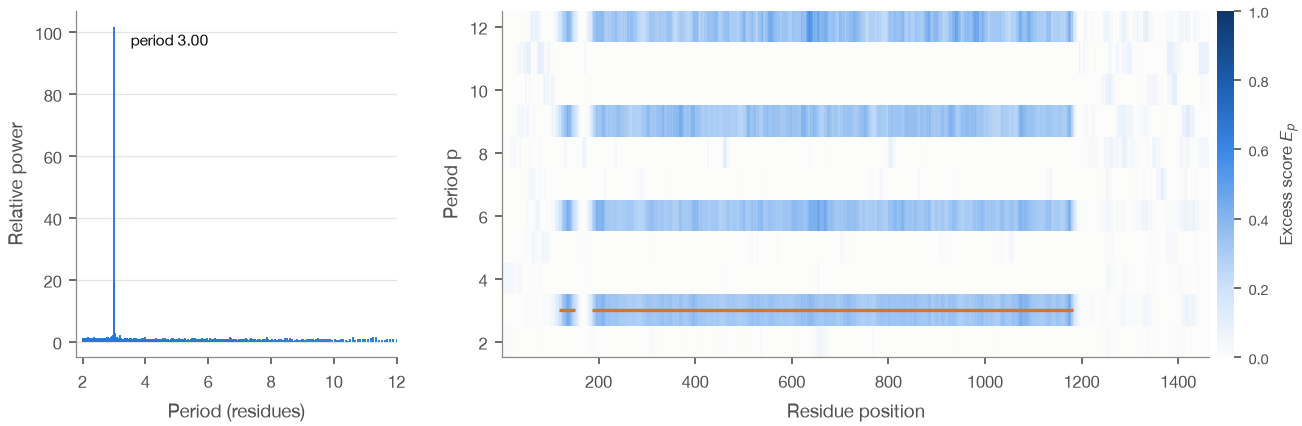

In [4]:
from aarepeats import periodic_regions

_, col = read_fasta(f"{DATA}/P02452.fasta")[0]
regions = periodic_regions(col)
print([(r.start + 1, r.end, r.period, round(r.mean_score, 2)) for r in regions])
fig, (a, b) = plt.subplots(1, 2, figsize=(10, 3), gridspec_kw=dict(width_ratios=[1, 2.3]))
P.plot_spectrum(*power_spectrum(col), ax=a)
P.plot_periodicity_map(local_periodicity(col, 2, 12, window=36), ax=b, regions=regions)
plt.show()